In [ ]:
# Task 1:
# 1) 9 Weights

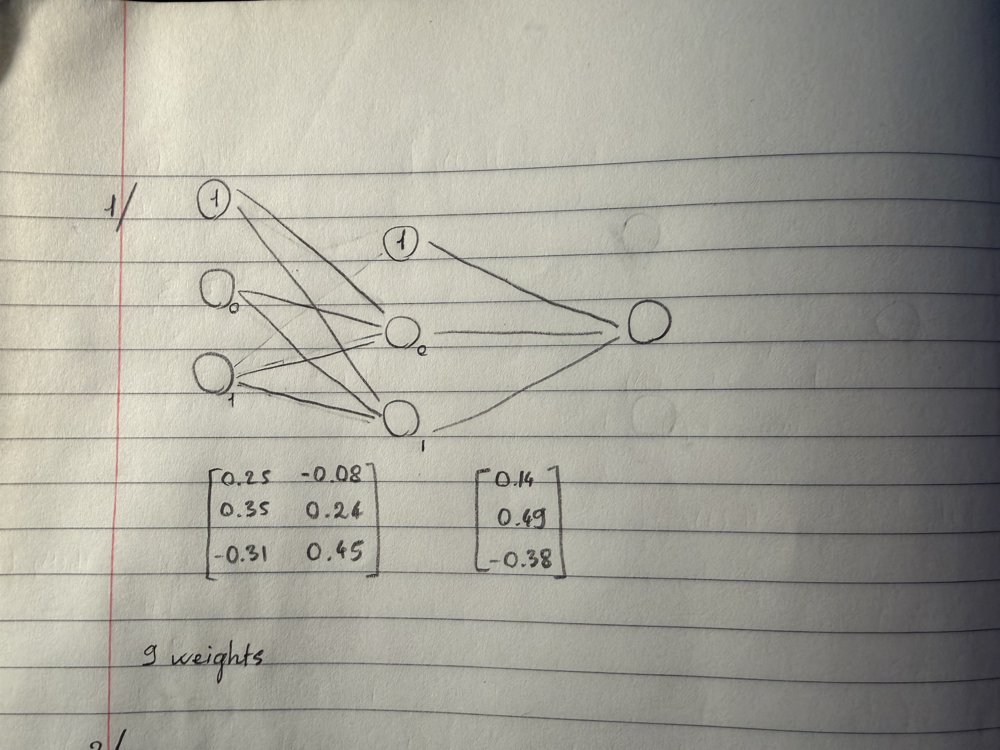

In [ ]:
# 2)

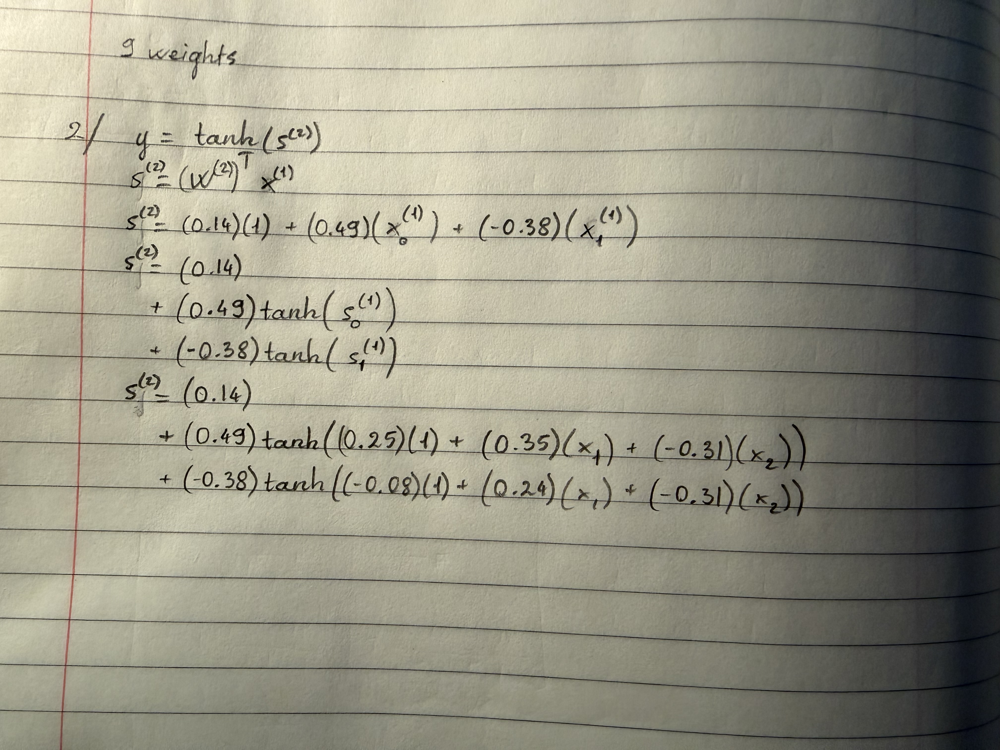

In [ ]:
# x2 = tanh(0.14
#          + 0.49 * tanh(0.25 + 0.35*0.5 + (-0.31)*(-1))
#          + (-0.38) * tanh(-0.08 + 0.24*0.5 + (-0.31)*(-1))
#     )

In [ ]:
# 3)
#    layer 1:
#        s_1 = 0.25 + 0.35*0.5 + (-0.31)*(-1) = 0.735
#        s_2 = -0.08 + 0.24*0.5 + (-0.31)*(-1) = 0.350
#        x_1 = tanh(s_1) = 0.626
#        x_2 = tanh(s_2) = 0.336
#    layer 2:
#        s = 0.14 + 0.49*x_1 + (-0.38)*x_2 = 0.319
#        x = tanh(s) = 0.309
#        the predicted class is +1, it is equal to the target
#        error = (0.309 - 1)^2 = 0.477
#        

In [ ]:
# 4, 5)

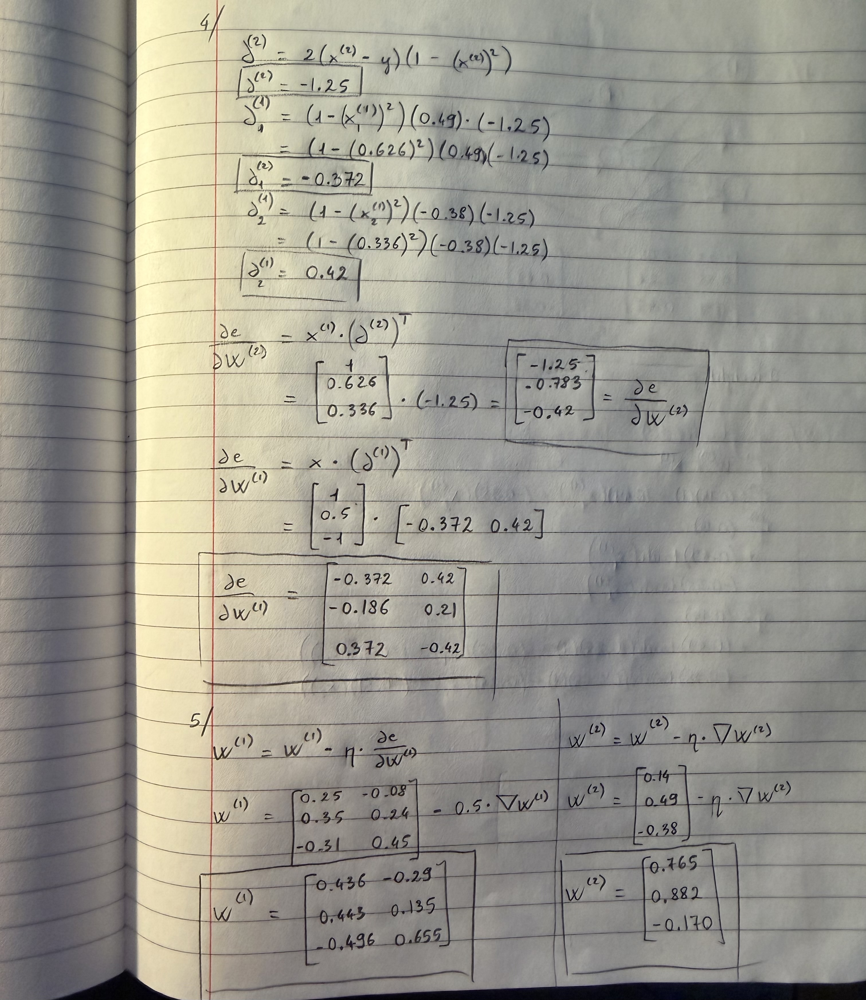

In [1]:
# 6)
#     x2 = tanh(0.765
#          + 0.882 * tanh(0.436 + 0.443*0.5 + (-0.496)*(-1))
#          + (-0.170) * tanh(-0.29 + 0.135*0.5 + (-0.655)*(-1))
#     )
#     x2 = 0.889
#     error = (0.889 - 1)^2 0.0123

In [2]:
# 7)
#    E did go down, weight w1 of layer 2 (0.882) has the largest magnitude, the gradient made it large.

In [91]:
# Task 2: (No Advance)
#
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

testing = False

In [92]:
"""Reference two-layer neural network for HW2 Task 2 (Core).

Use this if you skip Task 2 (Advanced). If you do the Advanced task, your own module must expose the same names and signatures,
so every Core step runs unchanged with `from my_nn import ...`.

Network: d inputs -> m hidden tanh units -> 1 tanh output. Squared error e = (output - y)^2, with y in {-1, +1}.
Convention (as in class): W[l] has shape (units_in + 1, units_out). Row 0 is the bias row. Column j is unit j.
"""
import numpy as np


def init_weights(sizes, seed=0, scale=0.1, zero=False):
    """sizes = [d, m, 1]. Returns a list [W1, W2]. zero=True gives the all-zero start (for the symmetry experiment)."""
    rng = np.random.default_rng(seed)
    Ws = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        Ws.append(np.zeros((n_in + 1, n_out)) if zero else scale * rng.standard_normal((n_in + 1, n_out)))
    return Ws


def forward(Ws, X):
    """X has shape (N, d). Returns the list of layer outputs [x(0), x(1), ..., x(L)], each of shape (N, units). Bias is not included."""
    xs = [X]
    for W in Ws:
        a = np.hstack([np.ones((len(xs[-1]), 1)), xs[-1]])
        xs.append(np.tanh(a @ W))
    return xs


def loss_and_grads(Ws, X, y):
    """Mean squared error over the rows of X, and its gradient for every W[l] (same shapes as Ws)."""
    xs = forward(Ws, X)
    N = len(X)
    out = xs[-1][:, 0]
    loss = np.mean((out - y) ** 2)
    delta = (2 * (out - y) * (1 - out ** 2))[:, None]             # sensitivity at the output, shape (N, 1)
    grads = [None] * len(Ws)
    for l in range(len(Ws) - 1, -1, -1):
        a = np.hstack([np.ones((N, 1)), xs[l]])                   # input of layer l with the bias column
        grads[l] = a.T @ delta / N
        if l > 0:
            delta = (delta @ Ws[l][1:].T) * (1 - xs[l] ** 2)      # drop the bias row, then multiply by tanh'
    return loss, grads


def predict(Ws, X):
    """Class labels in {-1, +1}: the sign of the output."""
    return np.where(forward(Ws, X)[-1][:, 0] >= 0, 1, -1)


def train_nn(X, y, m, batch_size, n_iters, eta, seed=0, record_every=100, zero_init=False):
    """Gradient descent on the whole training set X, y (y in {-1, +1}).
    Each iteration draws `batch_size` random rows (batch_size=1 is SGD, batch_size=len(X) is full-batch) and takes one step.
    Returns (Ws, history). history is a list of (iteration, E_in squared error, E_in classification error) measured on ALL of X.
    """
    rng = np.random.default_rng(seed)
    Ws = init_weights([X.shape[1], m, 1], seed=seed, zero=zero_init)
    history = []
    for it in range(n_iters + 1):
        if it % record_every == 0:
            loss, _ = loss_and_grads(Ws, X, y)
            history.append((it, loss, float(np.mean(predict(Ws, X) != y))))
        if it == n_iters:
            break
        idx = rng.choice(len(X), size=min(batch_size, len(X)), replace=False)
        _, grads = loss_and_grads(Ws, X[idx], y[idx])
        for W, g in zip(Ws, grads):
            W -= eta * g
    return Ws, history


def save_model(path, Ws, mean, std):
    """Weights plus the feature standardization (mean, std from the TRAINING set). This file is what we grade on the hidden test images."""
    np.savez(path, W1=Ws[0], W2=Ws[1], mean=mean, std=std)

In [93]:

# My code:

def scale_labels(labels):
    normalized = (labels - 1.0) / 4.0
    return np.array(normalized * 2.0 - 1.0)
    
def preprocess_data():
    df = pd.read_csv("zipdigits_1vs5_features.csv")
    intensity = df['intensity']
    symmetry = df['symmetry']
    label = df['label']
    features_by_row = np.transpose(np.array([intensity, symmetry]))
    
    X_train, X_test, y_train, y_test = train_test_split(
        features_by_row, 
        label,
        test_size = 0.3,
        random_state = 42,
        stratify = label
    )
    
    return X_train, X_test, scale_labels(y_train), scale_labels(y_test)

def plot_error_vs_iter(history, y_mark_threshold = 0.01):
    history_by_col = np.transpose(np.array(history))
    iters = history_by_col[0]
    E_in_squared = history_by_col[1]
    # find the y value threshold
    idx = np.argmin(np.abs(E_in_squared - y_mark_threshold))
    x_hit, y_hit = iters[idx], E_in_squared[idx]
    
    plt.plot(iters, E_in_squared)
    plt.plot(x_hit, y_hit, marker="o", markersize=4, color="red", label=f"Hit y={y_hit:.2f}")
    plt.xscale('log')

    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.xlabel("Iteration")
    plt.ylabel("E_in_squared")

    plt.show()
    
    

X_train, X_test, y_train, y_test = preprocess_data()
if testing:
    print("sanity check: y_train and y_test should be between -1 and 1: \n", y_train, y_test)

SGD model history (E_in^2 vs iterations)


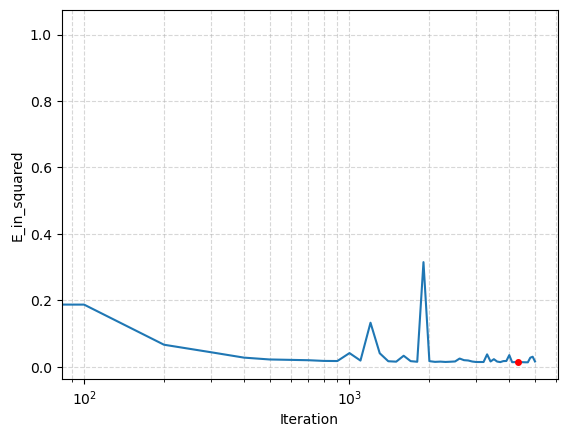

mini batch GD model history (E_in^2 vs iterations)


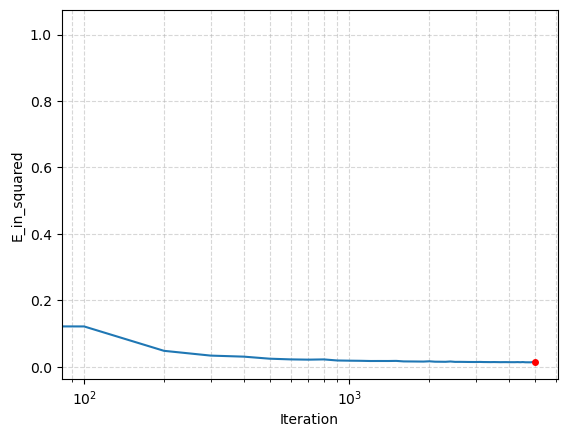

In [94]:
# 1) SGD vs mini batch
# I picked a learning rate of 0.01 because it was the only graph where the model training via SGD
# reached below 1% E_in.
learning_rate_list = [0.01, 0.1, 0.5]
learning_rate = learning_rate_list[1]
seed = 0     # ensure same seed for all runs

SGD_model, SGD_model_history = train_nn(
    X = X_train, 
    y = y_train, 
    m = 3, 
    batch_size = 1, 
    n_iters = 5000, 
    eta = learning_rate,
    seed = seed,
)
mini_model, mini_model_history = train_nn(
    X = X_train, 
    y = y_train, 
    m = 3, 
    batch_size = 32, 
    n_iters = 5000, 
    eta = learning_rate,
    seed = seed,
)

print("SGD model history (E_in^2 vs iterations)")
plot_error_vs_iter(SGD_model_history)
print("mini batch GD model history (E_in^2 vs iterations)")
plot_error_vs_iter(mini_model_history)

In [95]:
# 2) E_in and E_test
SGD_E_in = float(np.mean(predict(SGD_model, X_train) != y_train))
SGD_E_test = float(np.mean(predict(SGD_model, X_test) != y_test))
mini_E_in = float(np.mean(predict(mini_model, X_train) != y_train))
mini_E_test = float(np.mean(predict(mini_model, X_test) != y_test))

print("E_in vs E_test for SGD and mini batch gradient descent:")
print( "model      |E_in |E_test|")
print(f"SGD        |{SGD_E_in:.3f}|{SGD_E_test:.3f} |")
print(f"mini batch |{mini_E_in:.3f}|{mini_E_test:.3f} |")

E_in vs E_test for SGD and mini batch gradient descent:
model      |E_in |E_test|
SGD        |0.005|0.003 |
mini batch |0.004|0.000 |


mini batch GD model history (E_in^2 vs iterations), learning rate = 10


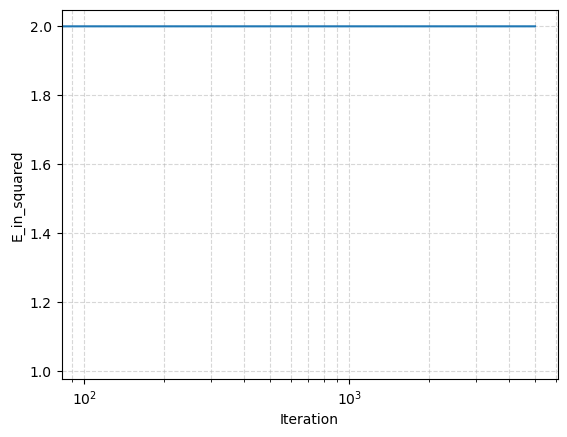

In [96]:

# 3) Learning rate = 10
mini_model_l10, mini_model_history_l10 = train_nn(
    X = X_train, 
    y = y_train, 
    m = 3, 
    batch_size = 32, 
    n_iters = 5000, 
    eta = 10,
    seed = seed,
)
print("mini batch GD model history (E_in^2 vs iterations), learning rate = 10")
plot_error_vs_iter(mini_model_history_l10)

In [97]:
# The curve does not converge to 0, it stays at a constant error.

mini batch GD model history (E_in^2 vs iterations), zero_init = true


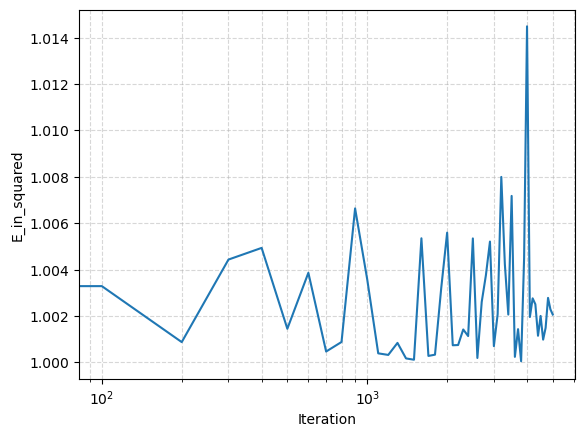

E_in, E_test = 0.5, 0.5


In [106]:
# 4) zero_init = True
mini_model_zi, mini_model_history_zi = train_nn(
    X = X_train, 
    y = y_train, 
    m = 3, 
    batch_size = 32, 
    n_iters = 5000, 
    eta = learning_rate,
    seed = seed,
    zero_init = True
)
print("mini batch GD model history (E_in^2 vs iterations), zero_init = true")
plot_error_vs_iter(mini_model_history_zi)

mini_zi_E_in = float(np.mean(predict(mini_model_zi, X_train) != y_train))
mini_zi_E_test = float(np.mean(predict(mini_model_zi, X_test) != y_test))
print(f"E_in, E_test = {mini_zi_E_in}, {mini_zi_E_test}")

In [104]:
# 5) Saving model
save_mean = np.mean(X_train)
save_stddev = np.std(X_train)
save_model("hw2_model.npz", mini_model, save_mean, save_stddev)
print(f"mean, stddev: {save_mean}, {save_stddev}")

mean, stddev: 0.418770675871626, 0.2829009748720827


In [108]:
# 6) SGD is noisier, because the gradient step is taken every iterations instead of culminating the error 
#  and taken after a batch of training data, so individual datapoints have more influence over the model's weights
#  and E_in.
#    Mini-batch would be faster to train because it only does backpropagation after a batch of 
#  training data instead of every training data set.

In [ ]:

# AI use disclaimer: 
#    I used Google's Gemini in the search bar, prompts:
#        "python f string limit decimal places"
#        "pandas standard deviation"
#        "pandas df mean"
#        "pyplot mark point when y hits a value"
#        "pyplot log10 plot"